Reading:
  /home/karimia1/social_fabric_vacc/github/figure4_plotdata.parquet


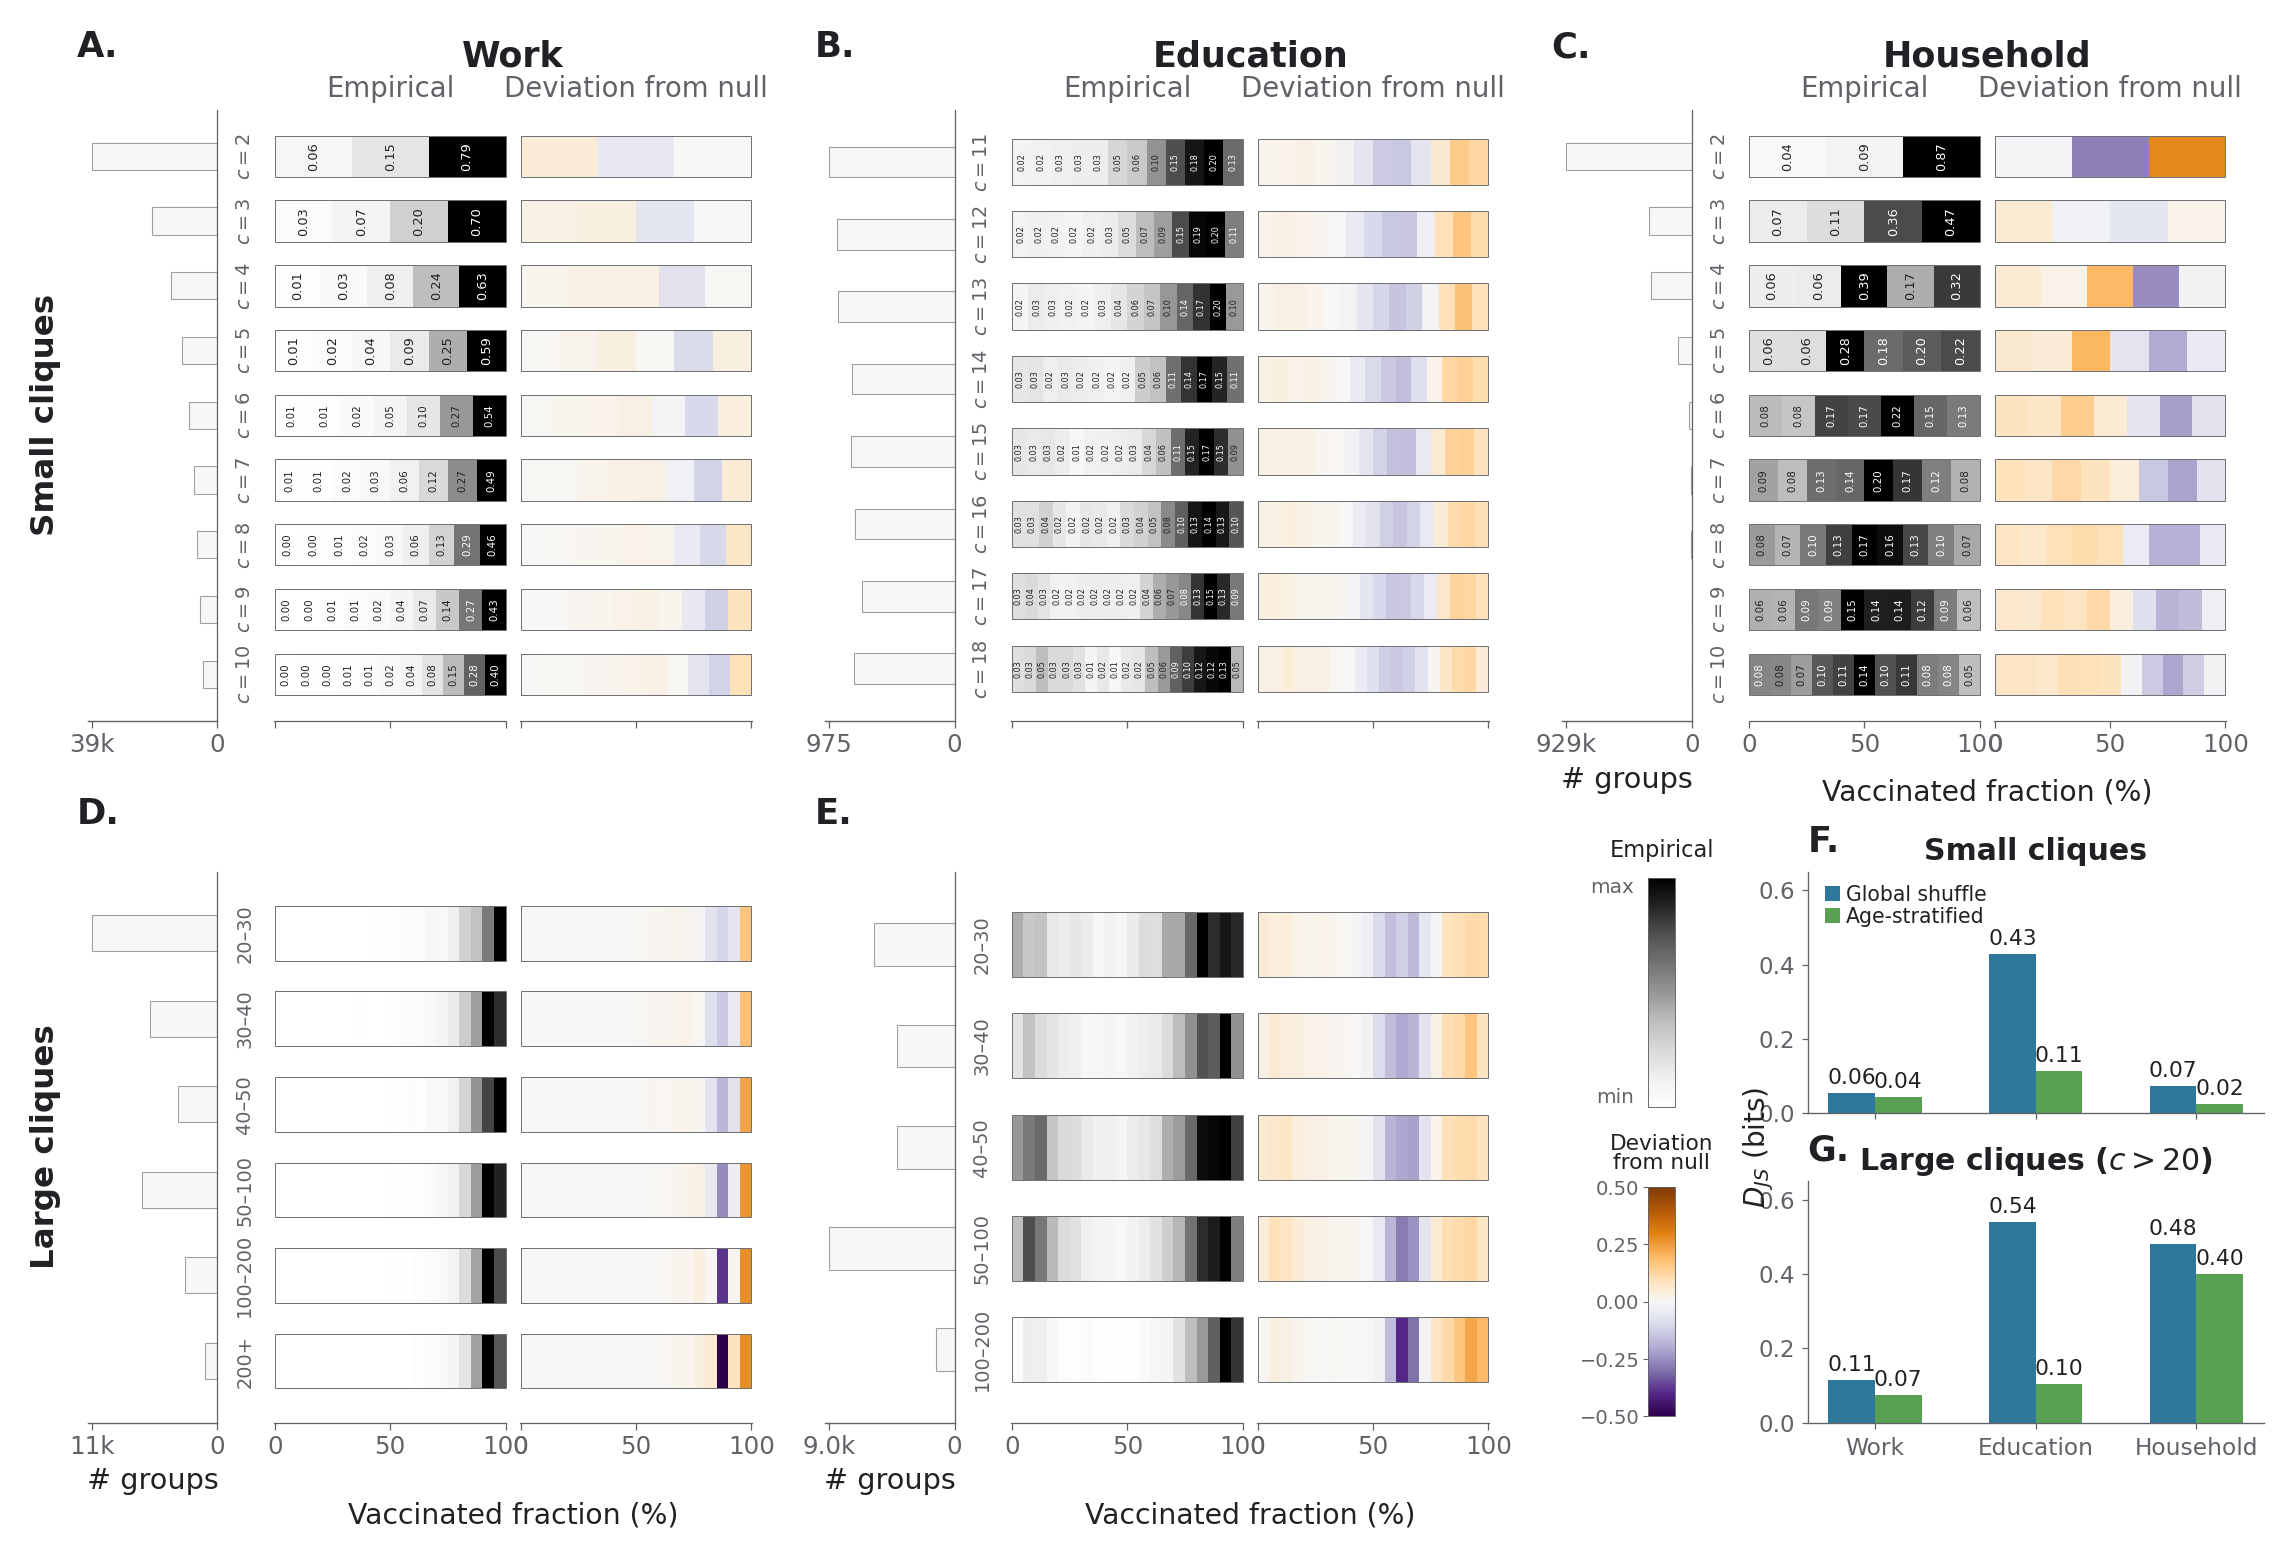

Saved:
  /home/karimia1/social_fabric_vacc/github/figure4.pdf


In [12]:
#!/usr/bin/env python3
"""Manuscript figure generated from saved plot-ready data.

Required input in the running directory:
    figure4_plotdata.parquet

Output:
    figure4.pdf
"""

from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd

import matplotlib
# Do not force the Agg backend: this keeps inline display working in Jupyter.
# On a headless cluster Matplotlib will normally choose a non-interactive backend automatically.

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib import cm, colors, font_manager
from matplotlib.ticker import MaxNLocator


# ============================================================
# Paths
# ============================================================

try:
    RUN_DIR = Path(__file__).resolve().parent
except NameError:
    RUN_DIR = Path.cwd()

PLOTDATA_FILE = RUN_DIR / "figure4_plotdata.parquet"

OUT_PDF = RUN_DIR / "figure4.pdf"

# ============================================================
# Constants
# ============================================================

CMAP_EMP = cm.Greys
CMAP_DIFF = cm.PuOr_r

NORM_EMP = colors.Normalize(vmin=0.0, vmax=1.0)
NORM_DIFF = colors.TwoSlopeNorm(vmin=-0.50, vcenter=0.0, vmax=0.50)

GLOBAL_COLOR = "#2f789b"
AGE_COLOR = "#5aa052"

# Neutral styling only. The scientific colour palette above is unchanged.
INK = "#202124"
MUTED = "#5f6368"
HAIR = "#9aa0a6"
LIGHT = "#f7f7f7"
BORDER = "#6f7377"

# The saved D_JS values are in nats; the manuscript reports bits.
DJS_VALUES_ARE_NATS = True


# ============================================================
# Style
# ============================================================

def choose_font() -> str:
    """Use the cleanest available sans-serif on the machine."""
    candidates = [
        "Helvetica Neue",
        "Arial",
        "Liberation Sans",
        "Nimbus Sans",
        "DejaVu Sans",
    ]
    for family in candidates:
        try:
            font_manager.findfont(family, fallback_to_default=False)
            return family
        except ValueError:
            pass
    return "DejaVu Sans"


FONT_FAMILY = choose_font()

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.sans-serif": [FONT_FAMILY],

    "mathtext.fontset": "custom",
    "mathtext.rm": FONT_FAMILY,
    "mathtext.it": f"{FONT_FAMILY}:italic",
    "mathtext.bf": f"{FONT_FAMILY}:bold",
    "mathtext.sf": FONT_FAMILY,
    "mathtext.tt": FONT_FAMILY,
    "mathtext.cal": FONT_FAMILY,
    "mathtext.fallback": "stixsans",

    "font.size": 7.1,
    "axes.titlesize": 7.5,
    "axes.labelsize": 6.9,
    "xtick.labelsize": 5.9,
    "ytick.labelsize": 5.9,
    "legend.fontsize": 5.2,

    "text.color": INK,
    "axes.labelcolor": INK,
    "axes.edgecolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,

    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "axes.linewidth": 0.34,

    "xtick.major.width": 0.30,
    "ytick.major.width": 0.30,
    "xtick.major.size": 1.7,
    "ytick.major.size": 1.7,

    "legend.frameon": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",

    "figure.dpi": 300,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# ============================================================
# Data helpers
# ============================================================

def fmt_count(n: float) -> str:
    n = float(n)

    if n >= 1_000_000:
        x = n / 1_000_000
        return f"{x:.1f}M" if x < 10 else f"{x:.0f}M"

    if n >= 1_000:
        x = n / 1_000
        return f"{x:.1f}k" if x < 10 else f"{x:.0f}k"

    return f"{n:.0f}"


def math_row_label(label: str) -> str:
    label = str(label)

    if label.startswith("c="):
        return r"$c=" + label.replace("c=", "") + "$"

    return label


def js_to_bits(x: float) -> float:
    x = float(x)
    if DJS_VALUES_ARE_NATS:
        return x / np.log(2.0)
    return x


def get_composition(
    plotdata: pd.DataFrame,
    layer_key: str,
    representation: str,
) -> pd.DataFrame:
    sub = plotdata[
        (plotdata["row_type"].astype(str) == "composition")
        & (plotdata["layer_key"].astype(str) == layer_key)
        & (plotdata["representation"].astype(str) == representation)
    ].copy()

    if sub.empty:
        raise ValueError(
            f"No composition data found for layer_key={layer_key}, "
            f"representation={representation}"
        )

    return sub


def get_js(
    plotdata: pd.DataFrame,
    representation: str,
) -> pd.DataFrame:
    sub = plotdata[
        (plotdata["row_type"].astype(str) == "js_bar")
        & (plotdata["representation"].astype(str) == representation)
    ].copy()

    if sub.empty:
        raise ValueError(f"No JSD data found for representation={representation}")

    return sub


# ============================================================
# Heatmap primitives
# ============================================================

def draw_counts_axis(
    ax,
    y_positions: np.ndarray,
    counts: list[float],
    nr: int,
    bar_h: float,
    show_xlabel: bool = True,
) -> None:
    cmax = max(counts) if counts else 1.0

    for y, n in zip(y_positions, counts):
        ax.barh(
            y,
            n,
            height=bar_h * 0.66,
            color=LIGHT,
            edgecolor=HAIR,
            linewidth=0.26,
            zorder=2,
        )

    ax.set_xlim(0, cmax * 1.035)
    ax.invert_xaxis()
    ax.set_ylim(-0.72, nr - 0.28)

    ax.set_yticks([])
    ax.set_xticks([0, cmax])
    ax.set_xticklabels(["0", fmt_count(cmax)])

    if show_xlabel:
        ax.set_xlabel("# groups", labelpad=2.0)
    else:
        ax.set_xlabel("")

    ax.spines["left"].set_visible(False)
    ax.spines["right"].set_visible(True)
    ax.spines["right"].set_linewidth(0.30)
    ax.spines["top"].set_visible(False)

    ax.tick_params(axis="x", length=1.6, pad=1.4)


def draw_label_axis(
    ax,
    y_positions: np.ndarray,
    row_labels: list[str],
    nr: int,
) -> None:
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.72, nr - 0.28)
    ax.axis("off")

    for y, lab in zip(y_positions, row_labels):
        ax.text(
            0.50,
            y,
            math_row_label(lab),
            rotation=90,
            ha="center",
            va="center",
            fontsize=4.65,
            fontweight="normal",
            color=MUTED,
        )


def draw_heat_rows(
    ax,
    sub: pd.DataFrame,
    row_orders: list[int],
    y_by_row: dict[int, float],
    value_col: str,
    cmap,
    norm,
    bar_h: float,
    annotate_values: bool = False,
) -> None:
    for row_order in row_orders:
        row = sub[sub["row_order"].astype(int) == int(row_order)].sort_values("x_left")
        y = y_by_row[int(row_order)]

        # Outer border only. No internal white segment separators.
        ax.add_patch(
            Rectangle(
                (0.0, y - bar_h / 2),
                1.0,
                bar_h,
                facecolor="none",
                edgecolor=BORDER,
                linewidth=0.24,
                zorder=5,
                clip_on=False,
            )
        )

        nseg = len(row)

        # All internal values are vertical, as in the dense manuscript panels.
        if nseg <= 6:
            text_fs = 3.10
        elif nseg <= 11:
            text_fs = 2.45
        else:
            text_fs = 1.95

        for _, r in row.iterrows():
            x0 = float(r["x_left"])
            x1 = float(r["x_right"])

            # Guard against clipping at exactly 0 or 1.
            x0 = max(0.0, x0)
            x1 = min(1.0, x1)
            width = max(0.0, x1 - x0)

            value = r[value_col]
            value = 0.0 if pd.isna(value) else float(value)

            ax.add_patch(
                Rectangle(
                    (x0, y - bar_h / 2),
                    width,
                    bar_h,
                    facecolor=cmap(norm(value)),
                    edgecolor="none",
                    linewidth=0.0,
                    zorder=2,
                    clip_on=False,
                )
            )

            if annotate_values:
                raw = r["real"]
                raw = 0.0 if pd.isna(raw) else float(raw)

                scaled = r["real_row_scaled"]
                scaled = 0.0 if pd.isna(scaled) else float(scaled)

                text_color = "white" if scaled > 0.55 else INK

                ax.text(
                    x0 + width / 2,
                    y,
                    f"{raw:.2f}",
                    ha="center",
                    va="center",
                    fontsize=text_fs,
                    rotation=90,
                    color=text_color,
                    zorder=6,
                    clip_on=True,
                )


def finish_heat_axis(
    ax,
    nr: int,
    show_xticklabels: bool,
    title: str | None = None,
) -> None:
    # Slightly padded x-limits prevent the right edge from looking cut.
    ax.set_xlim(-0.002, 1.002)
    ax.set_ylim(-0.72, nr - 0.28)
    ax.set_yticks([])
    ax.set_xticks([0, 0.5, 1.0])

    if show_xticklabels:
        ax.set_xticklabels(["0", "50", "100"])
    else:
        ax.set_xticklabels([])

    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

    ax.spines["bottom"].set_linewidth(0.30)
    ax.tick_params(axis="x", length=1.6, pad=1.4)

    if title is not None:
        ax.set_title(title, fontsize=6.6, fontweight="normal", color=MUTED, pad=3.0)


def draw_shared_fraction_xlabel(
    figure,
    x_emp: float,
    w_emp: float,
    x_diff: float,
    w_diff: float,
    bottom: float,
    dy: float,
) -> None:
    x_center = (x_emp + w_emp / 2 + x_diff + w_diff / 2) / 2

    figure.text(
        x_center,
        bottom - dy,
        "Vaccinated fraction (%)",
        ha="center",
        va="top",
        fontsize=6.8,
    )


def draw_heatmap_block(
    figure,
    rect: list[float],
    plotdata: pd.DataFrame,
    layer_key: str,
    representation: str,
    panel_label: str,
    layer_title: str | None,
    show_xlabel: bool,
    show_column_titles: bool,
    annotate_values: bool,
    show_counts_xlabel: bool = True,
    xlabel_dy: float = 0.045,
) -> None:
    """
    Draw one manuscript-style block.

    rect = [left, bottom, width, height] in figure coordinates.

    Internal layout:
        counts | row labels | empirical | gap | deviation

    Only one shared x-label is drawn below Empirical + Deviation.
    """
    sub = get_composition(plotdata, layer_key, representation)

    row_info = (
        sub.groupby("row_order", as_index=False)
        .agg(
            row_label=("row_label", "first"),
            n_groups=("n_groups", "max"),
        )
        .sort_values("row_order")
        .reset_index(drop=True)
    )

    row_orders = row_info["row_order"].astype(int).tolist()
    row_labels = row_info["row_label"].astype(str).tolist()
    counts = row_info["n_groups"].astype(float).tolist()

    nr = len(row_orders)
    y_positions = np.arange(nr)[::-1]
    y_by_row = dict(zip(row_orders, y_positions))

    left, bottom, width, height = rect

    # Same structure, but use the horizontal space more efficiently.
    x_counts = left
    w_counts = 0.185 * width

    x_labels = left + 0.198 * width
    w_labels = 0.052 * width

    x_emp = left + 0.266 * width
    w_emp = 0.330 * width

    x_diff = left + 0.616 * width
    w_diff = 0.330 * width

    row_h = 0.64

    ax_counts = figure.add_axes([x_counts, bottom, w_counts, height])
    ax_labels = figure.add_axes([x_labels, bottom, w_labels, height])
    ax_emp = figure.add_axes([x_emp, bottom, w_emp, height])
    ax_diff = figure.add_axes([x_diff, bottom, w_diff, height])

    draw_counts_axis(
        ax_counts,
        y_positions=y_positions,
        counts=counts,
        nr=nr,
        bar_h=row_h,
        show_xlabel=show_counts_xlabel,
    )

    draw_label_axis(
        ax_labels,
        y_positions=y_positions,
        row_labels=row_labels,
        nr=nr,
    )

    draw_heat_rows(
        ax_emp,
        sub=sub,
        row_orders=row_orders,
        y_by_row=y_by_row,
        value_col="real_row_scaled",
        cmap=CMAP_EMP,
        norm=NORM_EMP,
        bar_h=row_h,
        annotate_values=annotate_values,
    )

    draw_heat_rows(
        ax_diff,
        sub=sub,
        row_orders=row_orders,
        y_by_row=y_by_row,
        value_col="diff",
        cmap=CMAP_DIFF,
        norm=NORM_DIFF,
        bar_h=row_h,
        annotate_values=False,
    )

    finish_heat_axis(
        ax_emp,
        nr=nr,
        show_xticklabels=show_xlabel,
        title="Empirical" if show_column_titles else None,
    )

    finish_heat_axis(
        ax_diff,
        nr=nr,
        show_xticklabels=show_xlabel,
        title="Deviation from null" if show_column_titles else None,
    )

    if show_xlabel:
        draw_shared_fraction_xlabel(
            figure,
            x_emp=x_emp,
            w_emp=w_emp,
            x_diff=x_diff,
            w_diff=w_diff,
            bottom=bottom,
            dy=xlabel_dy,
        )

    ax_counts.text(
        -0.08,
        1.075,
        panel_label,
        transform=ax_counts.transAxes,
        ha="left",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
        clip_on=False,
    )

    if layer_title:
        # Center the layer heading over Empirical + Deviation as one visual unit.
        x_title = (x_emp + w_emp / 2 + x_diff + w_diff / 2) / 2
        figure.text(
            x_title,
            bottom + height + 0.024,
            layer_title,
            ha="center",
            va="bottom",
            fontsize=8.4,
            fontweight="bold",
            color=INK,
        )


# ============================================================
# Colour legends
# ============================================================

def draw_colourbars(figure, e_bottom: float, e_height: float, js_gap: float) -> None:
    """Compact legends in the dedicated gap between panel E and panels F/G."""
    js_h = (e_height - js_gap) / 2.0
    g_y = e_bottom
    f_y = e_bottom + js_h + js_gap

    cb_x = 0.697
    cb_w = 0.0115

    ax_emp = figure.add_axes([cb_x, f_y + 0.004, cb_w, js_h - 0.008])
    ax_diff = figure.add_axes([cb_x, g_y + 0.004, cb_w, js_h - 0.008])

    sm_emp = cm.ScalarMappable(norm=NORM_EMP, cmap=CMAP_EMP)
    sm_emp.set_array([])
    cb_emp = figure.colorbar(sm_emp, cax=ax_emp)
    cb_emp.outline.set_linewidth(0.22)
    cb_emp.set_ticks([])
    cb_emp.ax.tick_params(left=False, right=False, labelleft=False, labelright=False)

    ax_emp.set_title("Empirical", fontsize=5.4, pad=5.0, color=INK)
    ax_emp.text(
        -0.55, 1.00, "max",
        transform=ax_emp.transAxes,
        ha="right", va="top",
        fontsize=4.8, color=MUTED,
        clip_on=False,
    )
    ax_emp.text(
        -0.55, 0.00, "min",
        transform=ax_emp.transAxes,
        ha="right", va="bottom",
        fontsize=4.8, color=MUTED,
        clip_on=False,
    )

    sm_diff = cm.ScalarMappable(norm=NORM_DIFF, cmap=CMAP_DIFF)
    sm_diff.set_array([])
    cb_diff = figure.colorbar(sm_diff, cax=ax_diff)
    cb_diff.outline.set_linewidth(0.22)
    cb_diff.set_ticks([-0.50, -0.25, 0.00, 0.25, 0.50])

    cb_diff.ax.yaxis.set_ticks_position("left")
    cb_diff.ax.tick_params(
        labelsize=4.7,
        width=0.26,
        length=1.2,
        pad=1.0,
        labelleft=True,
        labelright=False,
    )
    ax_diff.set_title(
        "Deviation\nfrom null",
        fontsize=5.2,
        linespacing=0.92,
        pad=4.5,
        color=INK,
    )


# ============================================================
# JSD panels
# ============================================================

def draw_js_panel(
    ax,
    plotdata: pd.DataFrame,
    representation: str,
    panel_label: str,
    title: str,
    show_legend: bool,
    show_xticklabels: bool,
) -> None:
    sub = get_js(plotdata, representation)

    layers = ["Work", "Education", "Household"]
    x = np.arange(len(layers))
    width = 0.29

    vals_global = []
    vals_age = []

    for layer in layers:
        s = sub[sub["layer"].astype(str) == layer]

        g = s[s["null_model"].astype(str) == "Global shuffle"]
        a = s[s["null_model"].astype(str) == "Age-stratified"]

        vals_global.append(js_to_bits(g["value"].iloc[0]) if not g.empty else np.nan)
        vals_age.append(js_to_bits(a["value"].iloc[0]) if not a.empty else np.nan)

    bars_global = ax.bar(
        x - width / 2,
        vals_global,
        width=width,
        color=GLOBAL_COLOR,
        edgecolor="none",
        label="Global shuffle",
        zorder=2,
    )

    bars_age = ax.bar(
        x + width / 2,
        vals_age,
        width=width,
        color=AGE_COLOR,
        edgecolor="none",
        label="Age-stratified",
        zorder=2,
    )

    for bars in [bars_global, bars_age]:
        for bar in bars:
            h = bar.get_height()
            if np.isfinite(h):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    h + 0.014,
                    f"{h:.2f}",
                    ha="center",
                    va="bottom",
                    fontsize=5.25,
                    color=INK,
                )

    ax.set_ylim(0, 0.65)
    ax.set_yticks([0.0, 0.2, 0.4, 0.6])
    ax.set_ylabel("")

    ax.set_title(
        title,
        fontsize=7.2,
        fontweight="bold",
        pad=2.8,
        color=INK,
    )

    ax.set_xticks(x)
    if show_xticklabels:
        ax.set_xticklabels(layers, rotation=0, ha="center", fontsize=5.6)
    else:
        ax.set_xticklabels([])
        ax.tick_params(axis="x", length=0)

    ax.tick_params(axis="y", labelsize=5.5, pad=1.4, length=1.5)
    ax.tick_params(axis="x", pad=2.0, length=1.5)

    ax.grid(False)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.32)
        ax.spines[side].set_color(MUTED)

    ax.text(
        0.00,
        1.055,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=8.4,
        fontweight="bold",
        color=INK,
        clip_on=False,
    )

    if show_legend:
        ax.legend(
            loc="upper left",
            bbox_to_anchor=(0.02, 0.98),
            frameon=False,
            fontsize=4.9,
            handlelength=0.75,
            handleheight=0.75,
            handletextpad=0.28,
            labelspacing=0.08,
            borderaxespad=0.0,
        )


# ============================================================
# Main figure
# ============================================================

def make_figure(plotdata: pd.DataFrame) -> None:
    figure = plt.figure(figsize=(7.80, 5.03))

    # --------------------------------------------------------
    # A-C: small cliques
    # --------------------------------------------------------

    draw_heatmap_block(
        figure,
        rect=[0.030, 0.535, 0.300, 0.405],
        plotdata=plotdata,
        layer_key="work",
        representation="small",
        panel_label="A.",
        layer_title="Work",
        show_xlabel=False,
        show_column_titles=True,
        annotate_values=True,
        show_counts_xlabel=False,
    )

    draw_heatmap_block(
        figure,
        rect=[0.345, 0.535, 0.300, 0.405],
        plotdata=plotdata,
        layer_key="school_new",
        representation="small",
        panel_label="B.",
        layer_title="Education",
        show_xlabel=False,
        show_column_titles=True,
        annotate_values=True,
        show_counts_xlabel=False,
    )

    draw_heatmap_block(
        figure,
        rect=[0.660, 0.535, 0.300, 0.405],
        plotdata=plotdata,
        layer_key="house",
        representation="small",
        panel_label="C.",
        layer_title="Household",
        show_xlabel=True,
        show_column_titles=True,
        annotate_values=True,
        show_counts_xlabel=True,
        xlabel_dy=0.038,
    )

    # --------------------------------------------------------
    # D-E: large cliques
    # --------------------------------------------------------

    e_bottom = 0.070
    e_height = 0.365

    draw_heatmap_block(
        figure,
        rect=[0.030, e_bottom, 0.300, e_height],
        plotdata=plotdata,
        layer_key="work",
        representation="large",
        panel_label="D.",
        layer_title=None,
        show_xlabel=True,
        show_column_titles=False,
        annotate_values=False,
        show_counts_xlabel=True,
        xlabel_dy=0.052,
    )

    draw_heatmap_block(
        figure,
        rect=[0.345, e_bottom, 0.300, e_height],
        plotdata=plotdata,
        layer_key="school_new",
        representation="large",
        panel_label="E.",
        layer_title=None,
        show_xlabel=True,
        show_column_titles=False,
        annotate_values=False,
        show_counts_xlabel=True,
        xlabel_dy=0.052,
    )

    # --------------------------------------------------------
    # Colour bars and F/G
    # F + G combined vertical span equals panel E.
    # --------------------------------------------------------

    js_gap = 0.045
    js_h = (e_height - js_gap) / 2.0
    js_x = 0.765
    js_w = 0.195

    g_y = e_bottom
    f_y = e_bottom + js_h + js_gap

    draw_colourbars(figure, e_bottom=e_bottom, e_height=e_height, js_gap=js_gap)

    figure.text(
        0.744,
        e_bottom + e_height / 2,
        r"$D_{JS}$ (bits)",
        rotation=90,
        ha="center",
        va="center",
        fontsize=6.7,
        color=INK,
    )

    ax_f = figure.add_axes([js_x, f_y, js_w, js_h])
    draw_js_panel(
        ax_f,
        plotdata,
        representation="small",
        panel_label="F.",
        title="Small cliques",
        show_legend=True,
        show_xticklabels=False,
    )

    ax_g = figure.add_axes([js_x, g_y, js_w, js_h])
    draw_js_panel(
        ax_g,
        plotdata,
        representation="large",
        panel_label="G.",
        title=r"Large cliques ($c > 20$)",
        show_legend=False,
        show_xticklabels=True,
    )

    # --------------------------------------------------------
    # Row labels
    # --------------------------------------------------------

    figure.text(
        0.012,
        0.738,
        "Small cliques",
        rotation=90,
        ha="center",
        va="center",
        fontsize=7.8,
        fontweight="bold",
    )

    figure.text(
        0.012,
        0.253,
        "Large cliques",
        rotation=90,
        ha="center",
        va="center",
        fontsize=7.8,
        fontweight="bold",
    )


    # Save first, then display inline in Jupyter.
    figure.savefig(OUT_PDF, bbox_inches="tight", pad_inches=0.025)
    plt.show()
    plt.close(figure)

    print("Saved:")
    print(f"  {OUT_PDF}")

    


# ============================================================
# Run
# ============================================================

def main() -> None:
    if not PLOTDATA_FILE.exists():
        raise FileNotFoundError(
            f"Could not find:\n  {PLOTDATA_FILE}\n\n"
            "Put figure4_plotdata.parquet in the same folder as this script/notebook."
        )

    print("Reading:")
    print(f"  {PLOTDATA_FILE}")

    plotdata = pd.read_parquet(PLOTDATA_FILE)

    required_cols = [
        "row_type",
        "representation",
        "layer_key",
        "layer",
        "row_order",
        "row_label",
        "x_left",
        "x_right",
        "n_groups",
        "real",
        "real_row_scaled",
        "diff",
        "null_model",
        "value",
    ]

    missing = [c for c in required_cols if c not in plotdata.columns]
    if missing:
        raise ValueError(
            "Plot-data file is missing required columns:\n"
            + "\n".join(f"  - {c}" for c in missing)
        )

    make_figure(plotdata)


main()